In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
filename = "G:/neural_network_from_scratch/heart diseases/heart.csv"
df = pd.read_csv(filename)
df.head(1)

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0


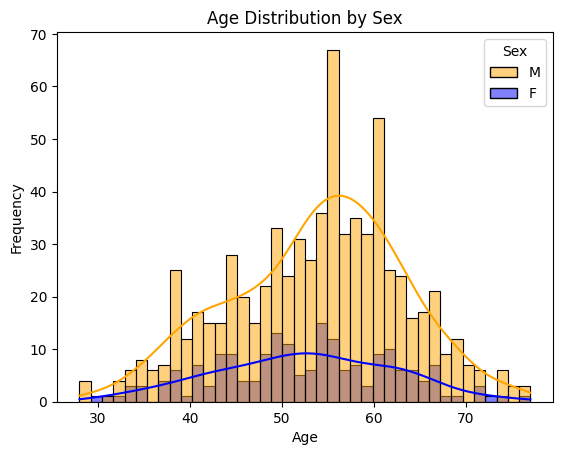

In [3]:
# age sex distribution
sns.histplot(
    df,
    x='Age',
    hue='Sex',
    kde=True,
    bins=40,
    palette={'M': 'orange', 'F': 'blue'}
)
plt.title("Age Distribution by Sex")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

In [4]:
#chest pain type vs heart disease
chest_pain_df = df.groupby(['ChestPainType','HeartDisease']).size().reset_index(name="count")
chest_pain_df

,ChestPainType,HeartDisease,count
0,ASY,0,104
1,ASY,1,392
2,ATA,0,149
3,ATA,1,24
4,NAP,0,131
5,NAP,1,72
6,TA,0,26
7,TA,1,20


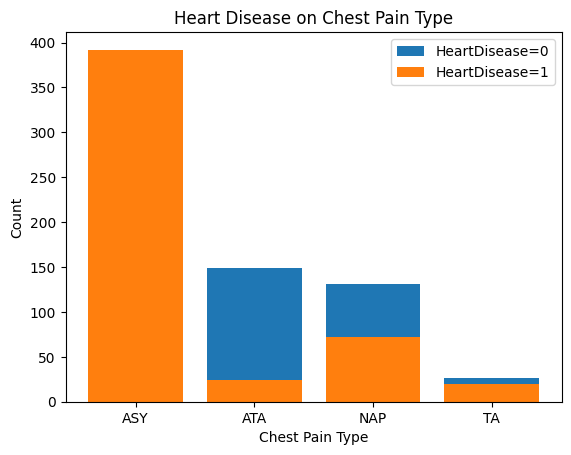

In [5]:
# chest pain vs heart disease
cat_chest_pain = chest_pain_df['ChestPainType'].unique()

for disease_status in chest_pain_df['HeartDisease'].unique():
    subset = chest_pain_df[chest_pain_df['HeartDisease'] == disease_status]
    plt.bar(subset['ChestPainType'],subset['count'],label=f'HeartDisease={disease_status}')

plt.title("Heart Disease on Chest Pain Type")
plt.xlabel("Chest Pain Type")
plt.ylabel("Count")
plt.xticks(cat_chest_pain)
plt.legend()
plt.show()

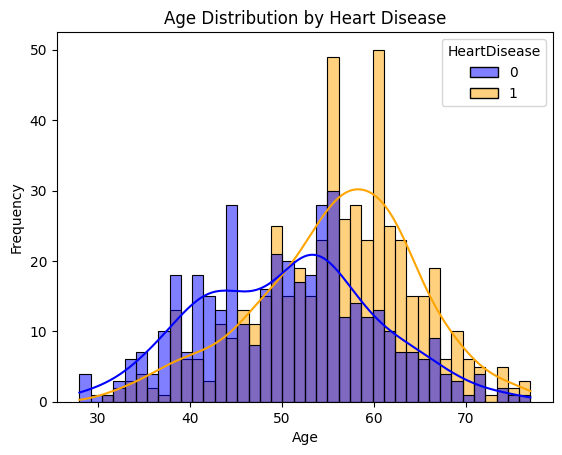

In [7]:
# age heart disease distribution
sns.histplot(
    df,
    x='Age',
    hue='HeartDisease',
    kde=True,
    bins=40,
    palette={1: 'orange', 0: 'blue'}
)
plt.title("Age Distribution by Heart Disease")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

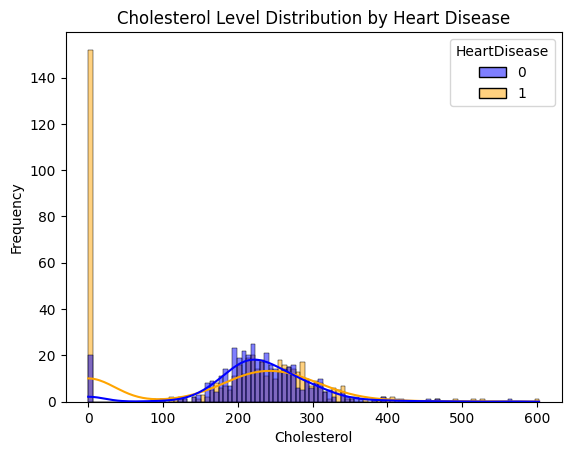

In [22]:
# cholesterol distribution
sns.histplot(
    df,
    x='Cholesterol',
    hue='HeartDisease',
    kde=True,
    bins=100,
    palette={1: 'orange', 0: 'blue'}
)
plt.title("Cholesterol Level Distribution by Heart Disease")
plt.xlabel("Cholesterol")
plt.ylabel("Frequency")
plt.show()

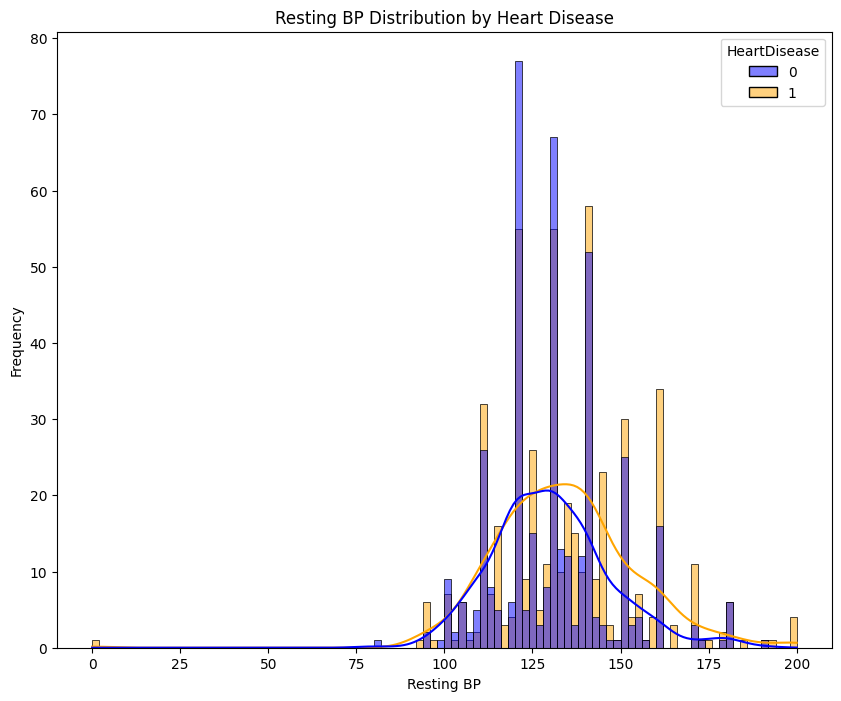

In [21]:
# Resting BP distribution
plt.figure(figsize=(10,8))
sns.histplot(
    df,
    x='RestingBP',
    hue='HeartDisease',
    kde=True,
    bins=100,
    palette={1: 'orange', 0: 'blue'}
)
plt.title("Resting BP Distribution by Heart Disease")
plt.xlabel("Resting BP")
plt.ylabel("Frequency")
plt.show()

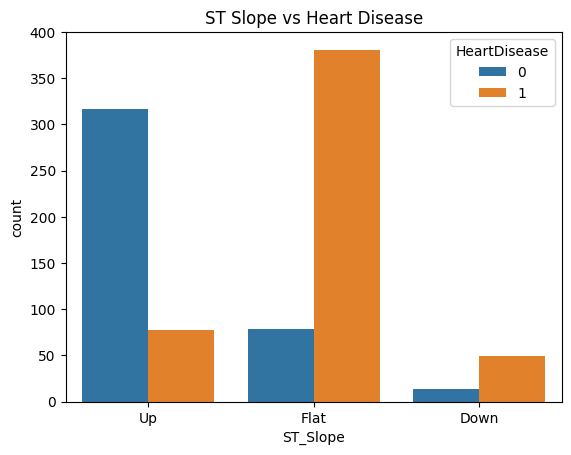

In [10]:
sns.countplot(
    data=df,
    x='ST_Slope',
    hue='HeartDisease'
)

plt.title('ST Slope vs Heart Disease')
plt.show()

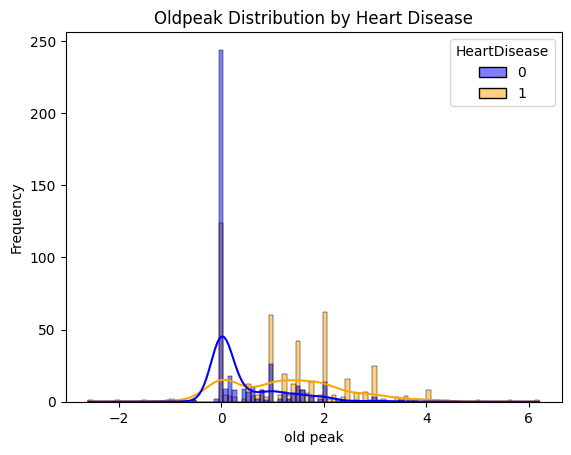

In [19]:
# old peak distribution
sns.histplot(
    df,
    x='Oldpeak',
    hue='HeartDisease',
    kde=True,
    bins=100,
    palette={1: 'orange', 0: 'blue'}
)
plt.title("Oldpeak Distribution by Heart Disease")
plt.xlabel("old peak")
plt.ylabel("Frequency")
plt.show()

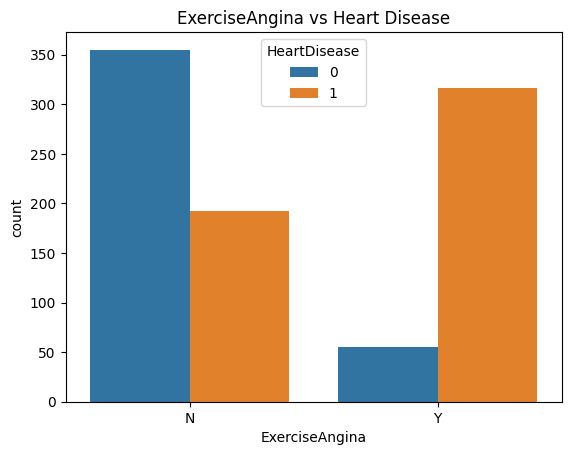

In [13]:
sns.countplot(
    data=df,
    x='ExerciseAngina',
    hue='HeartDisease'
)

plt.title('ExerciseAngina vs Heart Disease') # exercise angina is a physical pain that a person experiences during an exercise
plt.show()

In [17]:
data_resting_ecg = df.groupby(['RestingECG','HeartDisease']).size().reset_index(name="count")
data_resting_ecg

,RestingECG,HeartDisease,count
0,LVH,0,82
1,LVH,1,106
2,Normal,0,267
3,Normal,1,285
4,ST,0,61
5,ST,1,117


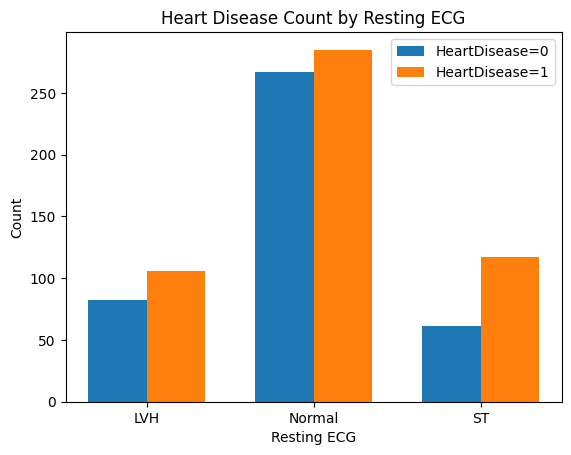

In [18]:
ecg_types = data_resting_ecg['RestingECG'].unique()
x = np.arange(len(ecg_types))
width = 0.35

subset_0 = data_resting_ecg[data_resting_ecg['HeartDisease'] == 0].set_index('RestingECG')['count']
subset_1 = data_resting_ecg[data_resting_ecg['HeartDisease'] == 1].set_index('RestingECG')['count']

plt.bar(x - width/2, subset_0.reindex(ecg_types, fill_value=0), width, label='HeartDisease=0')
plt.bar(x + width/2, subset_1.reindex(ecg_types, fill_value=0), width, label='HeartDisease=1')

plt.xlabel('Resting ECG')
plt.ylabel('Count')
plt.title('Heart Disease Count by Resting ECG')
plt.xticks(x, ecg_types)
plt.legend()
plt.show()

In [ ]:
'''
    Noted key features:
    Age, Chest Pain Type, Sex, Resting BP, Old Peak, exercise angina, ST_Slope
'''